# Performance evaluation for **XenofilteR**

In this notebook, we evaluate the read-sorting performance of XenofilteR for whole-genome bisulfite mouse/human in silico mixtures. 

We used two different parameter settings to run XenofilteR:
- MM_Threshold = 4 (default)
- MM_Threshold = 8, which is preferred for longer reads (e.g. 100bp or 150bp)

XenofilteR performs xenograft-sorting by only retaining human-classified reads by using a dual-alignment approach. The remaining reads are discarded. 

## 0. Imports and path assignments

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

from warnings import simplefilter
simplefilter("ignore")

In [2]:
# --- Parameters ---
data_dir = Path("/omics/groups/OE0219/internal/altendorfer/epiproper/read_sorting_benchmark/data")
method = "xenofilter"
fig_dir = Path.cwd() / "figures" / method
fig_dir.mkdir(exist_ok=True, parents=True)

## 1. Load data

In [3]:
df = read_evaluations(data_dir, method)
df_mm8 = read_evaluations(data_dir, "xenofilter_mm8").drop_duplicates()
df.groupby(["Sample_Prefix", "Total_Reads"]).count()
df_mm8.groupby(["Sample_Prefix", "Total_Reads"]).count()

ID  Mixture  \
Sample_Prefix                                      Total_Reads                
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000     54       54   
                                                   100000000    54       54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000     54       54   
                                                   100000000    54       54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000     54       54   
                                                   100000000    54       54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000     54       54   
                                                   100000000    54       54   

                                                                Replicate  \
Sample_Prefix                                      Total_Reads              
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000            54   
                                                   100000000           54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000            54   
                                                   100000000           54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000            54   
                                                   100000000           54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000            54   
                                                   100000000           54   

                                                                Human_Assigned  \
Sample_Prefix                                      Total_Reads                   
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   

                                                                Human_Human  \
Sample_Prefix                                      Total_Reads                
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000              54   
                                                   100000000             54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000              54   
                                                   100000000             54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000              54   
                                                   100000000             54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000              54   
                                                   100000000             54   

                                                                Human_Mouse  \
Sample_Prefix                                      Total_Reads                
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000              54   
                                                   100000000             54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000              54   
                                                   100000000             54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000              54   
                                                   100000000             54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000              54   
                                                   100000000             54   

                                                                Mouse_Mouse  \
Sample_Prefix       

In [4]:
df["Human_Ratio"] = [float(s.rstrip('p')) for s in df["Mixture"] ]
df_mm8["Human_Ratio"] = [float(s.rstrip('p')) for s in df_mm8["Mixture"] ]

## Visualize assigned reads

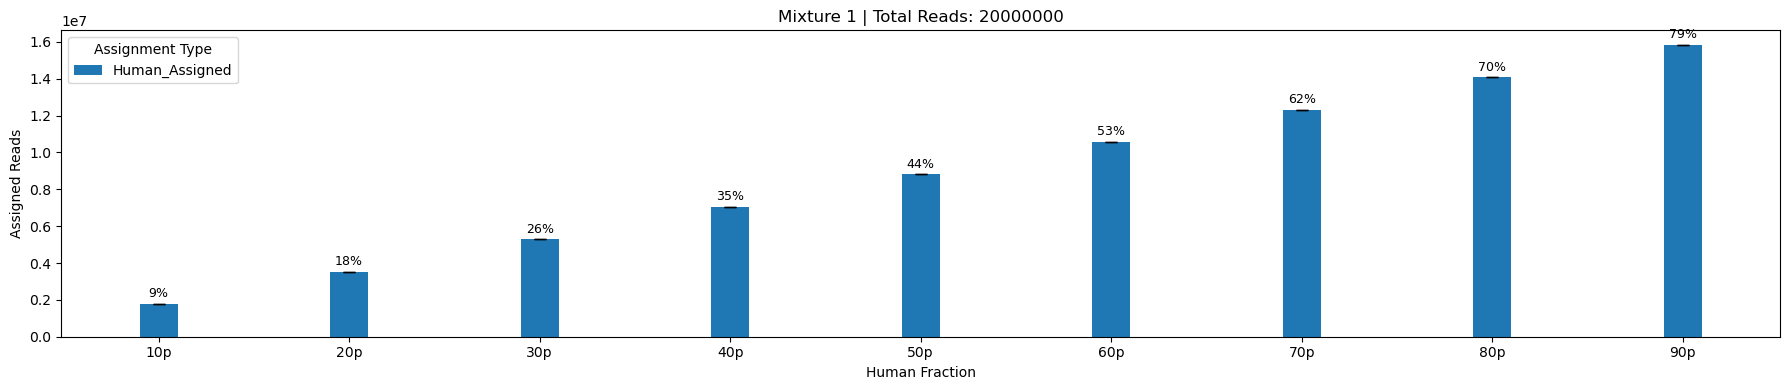

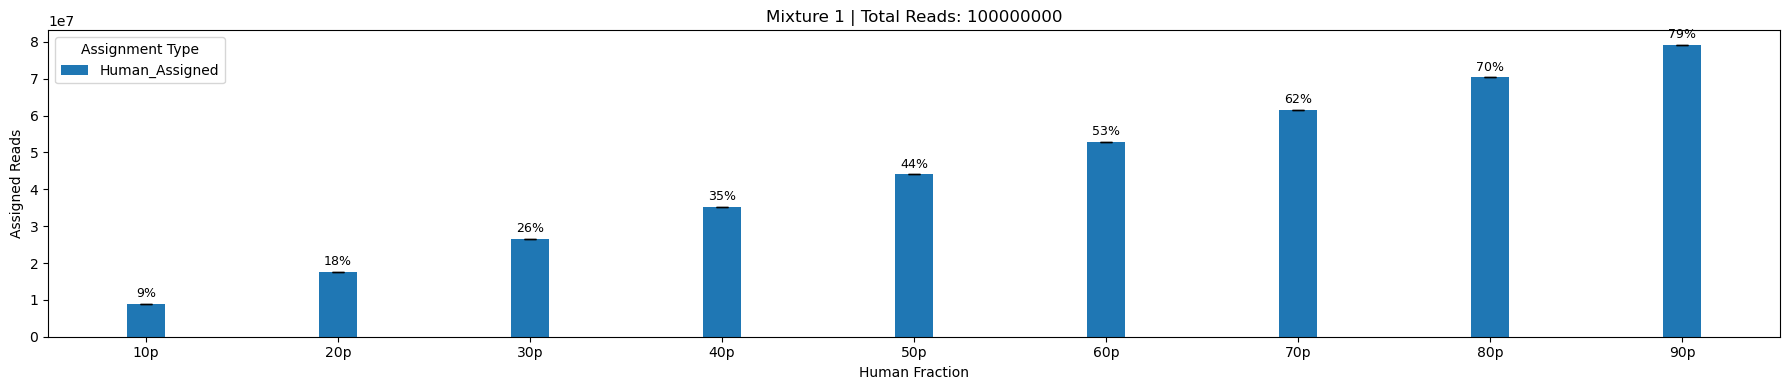

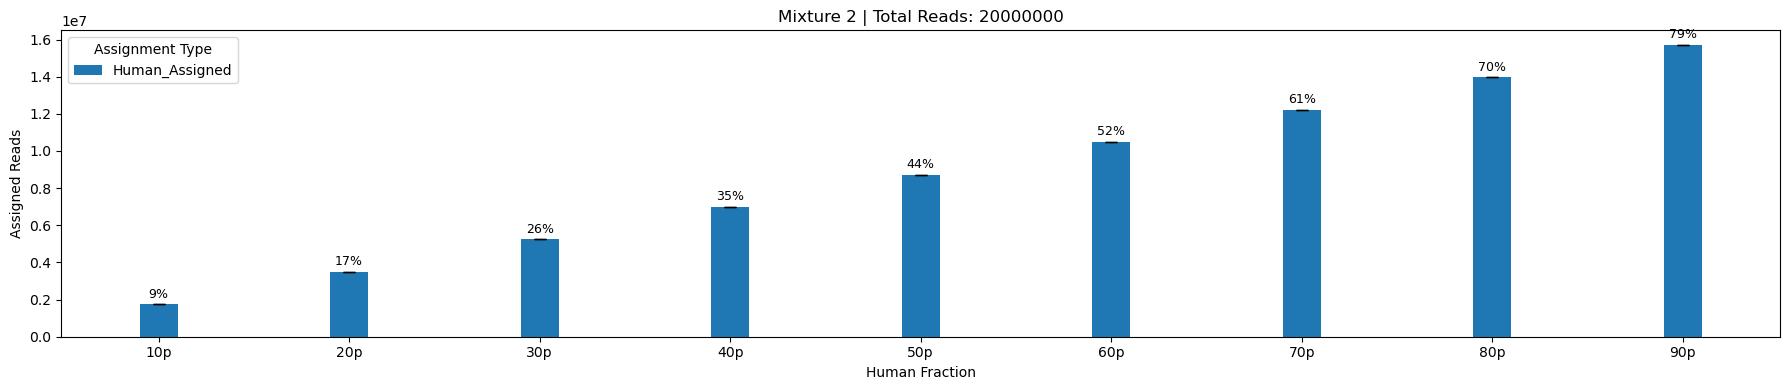

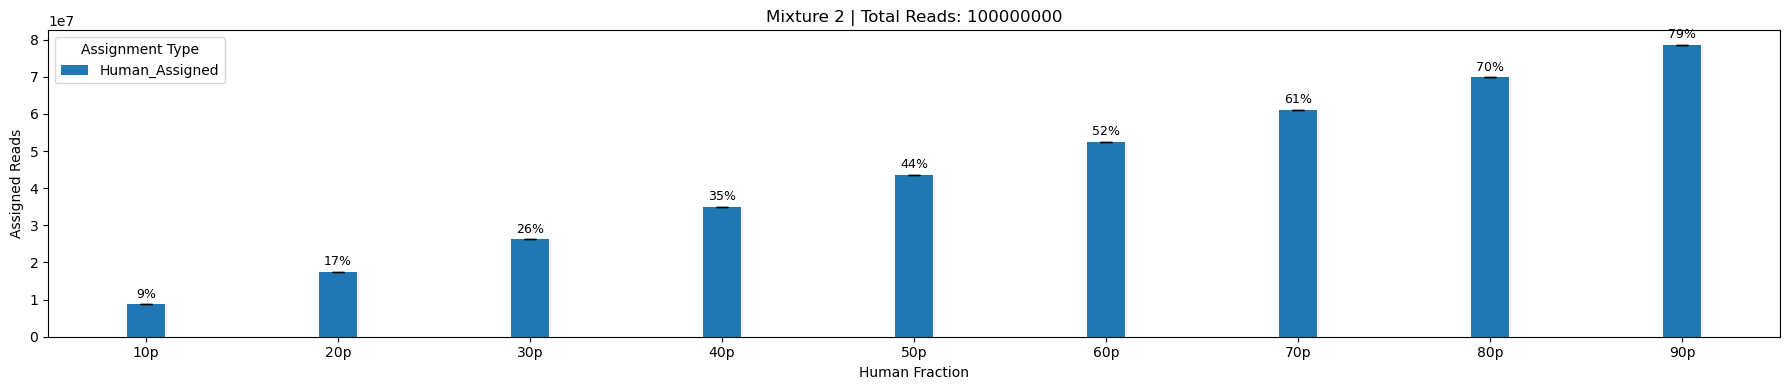

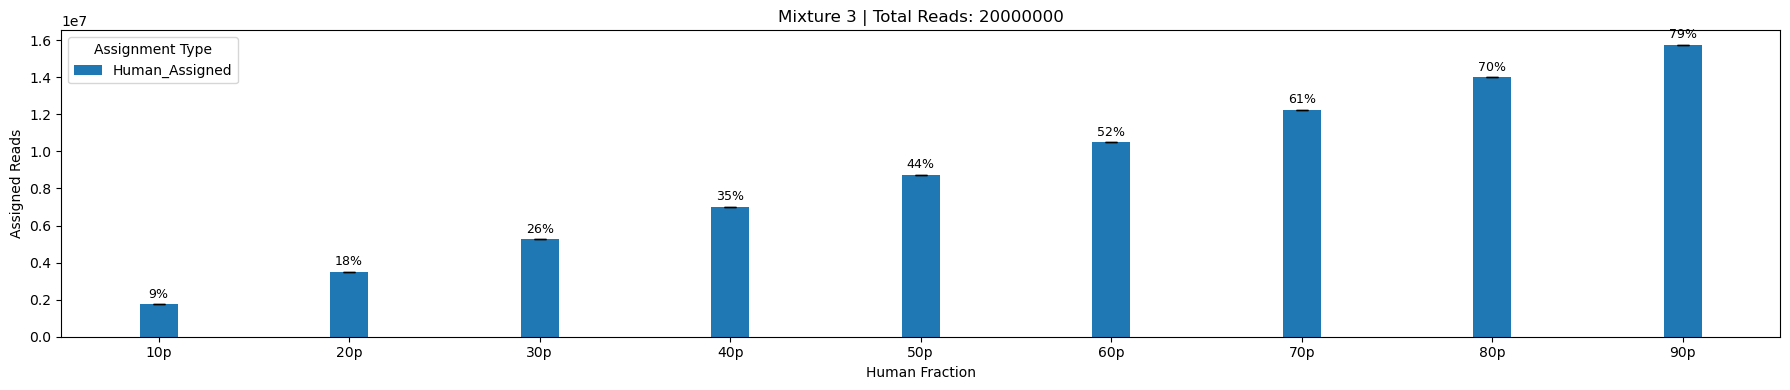

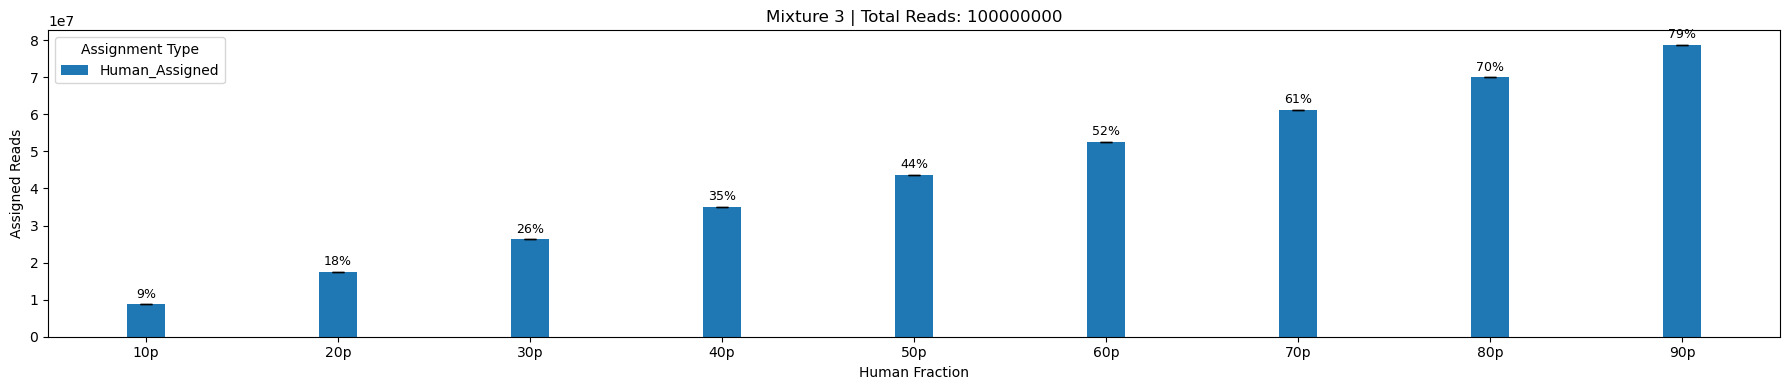

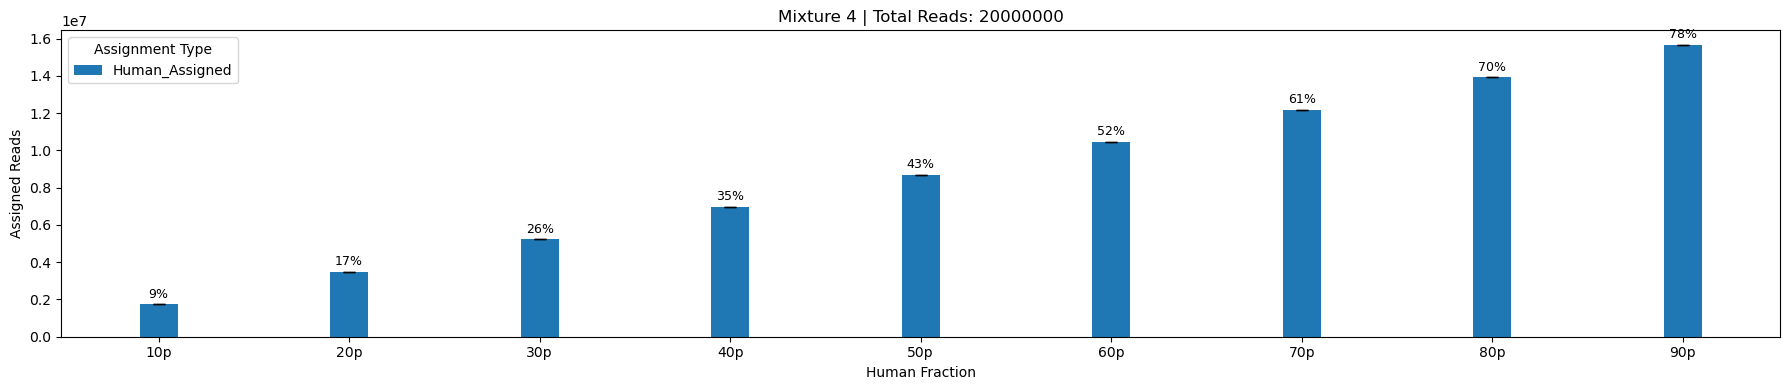

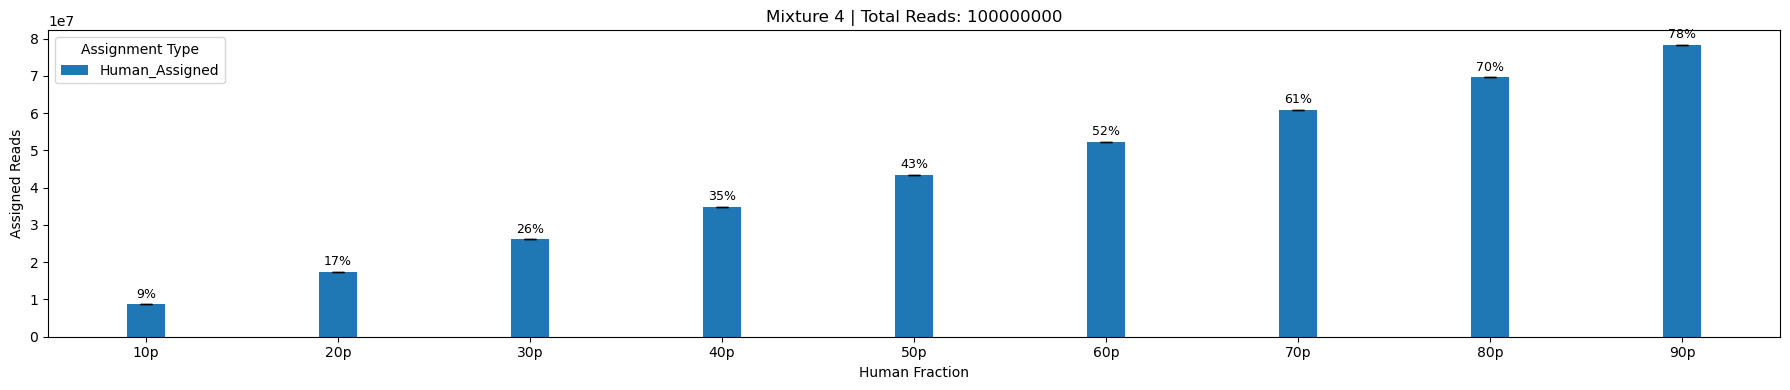

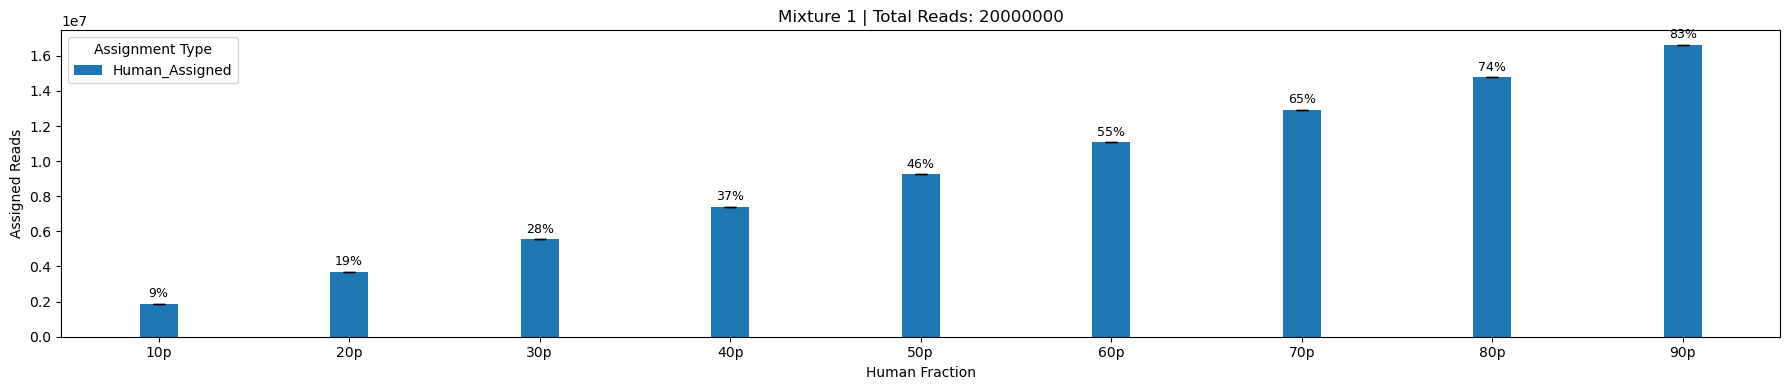

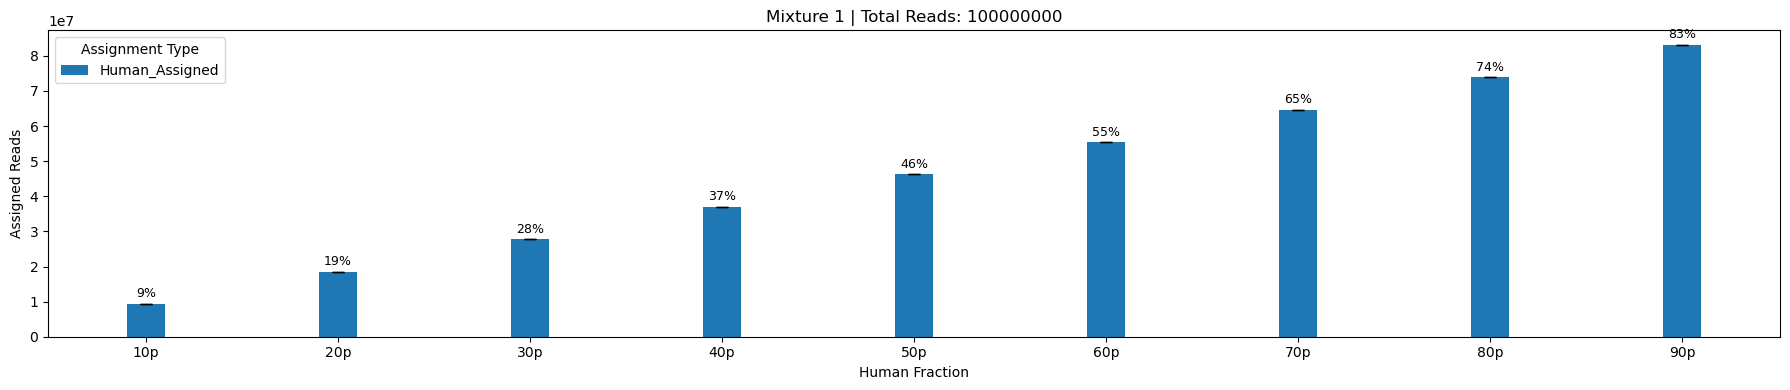

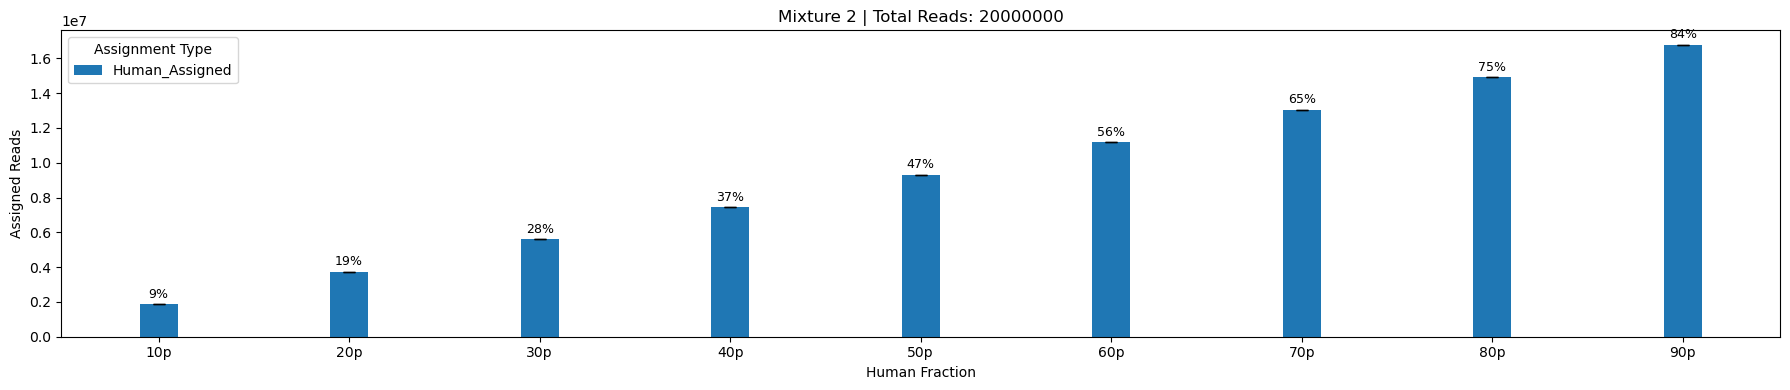

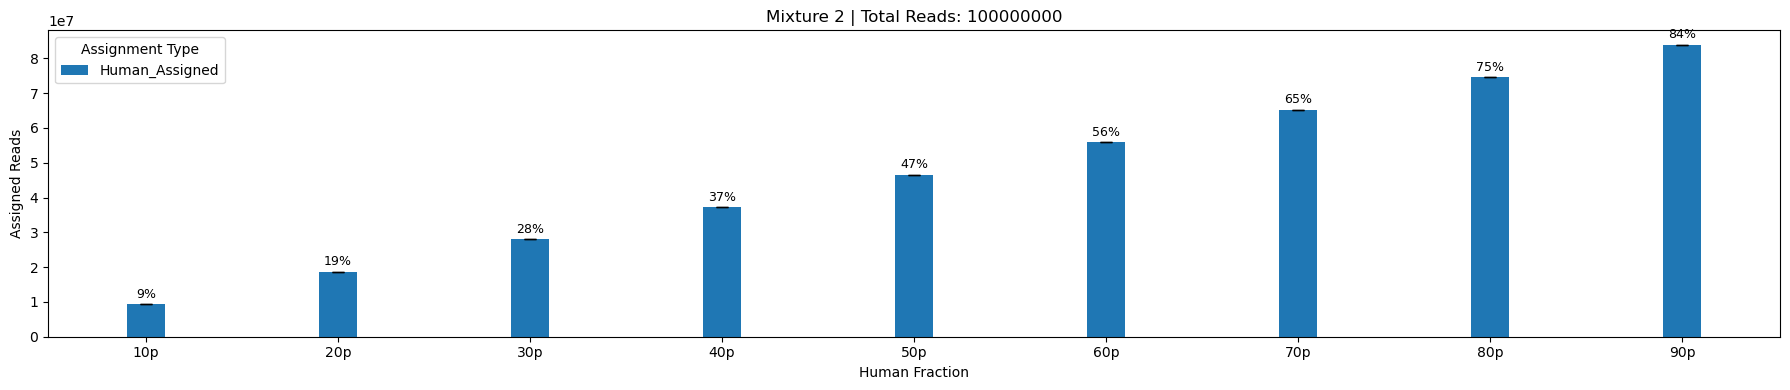

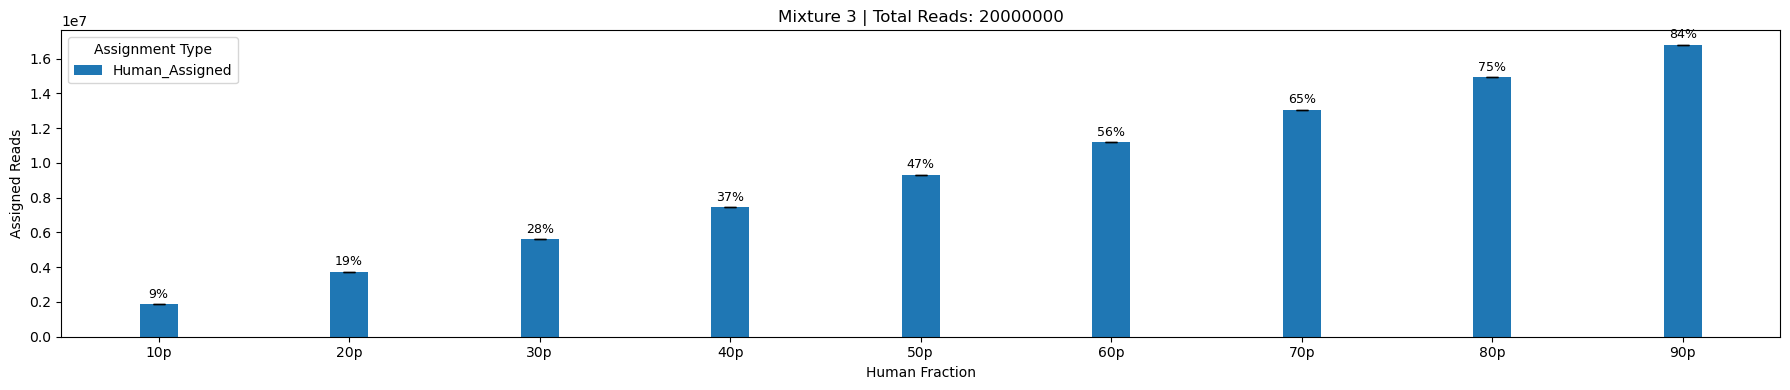

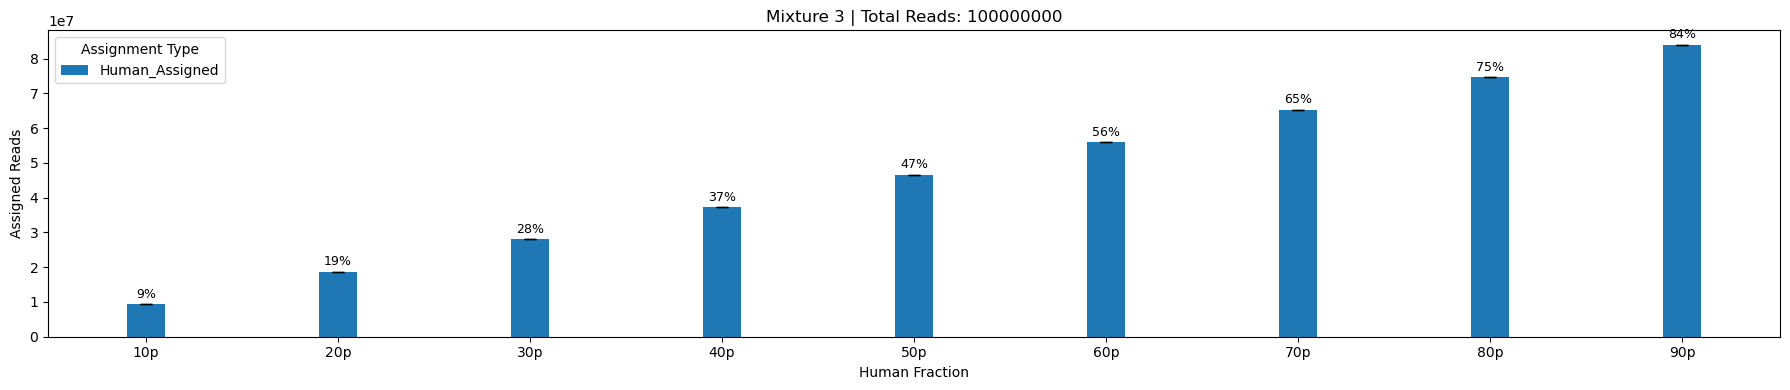

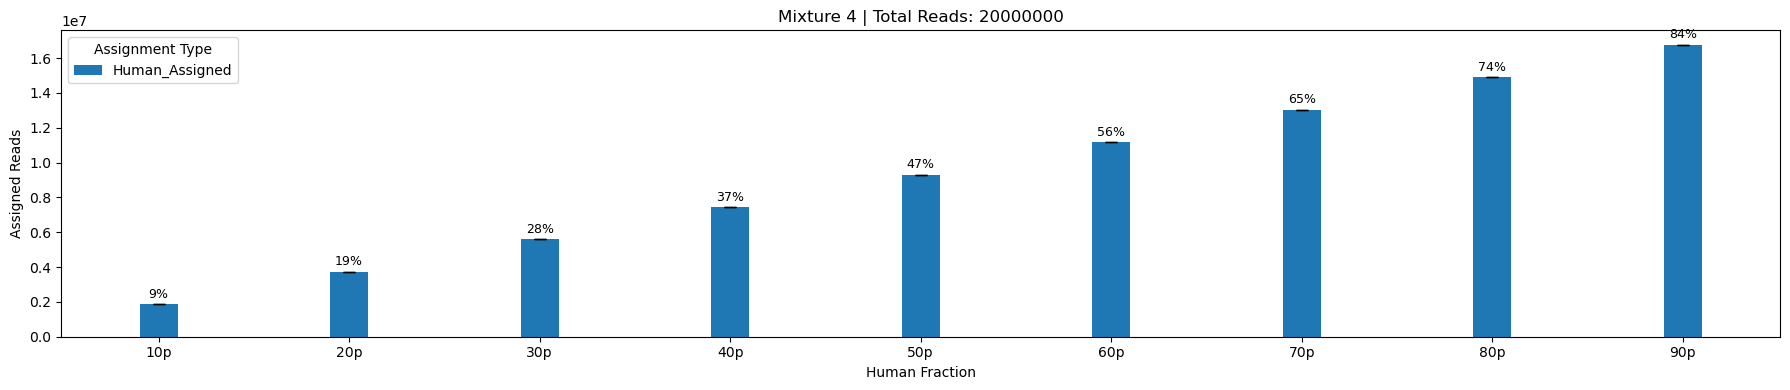

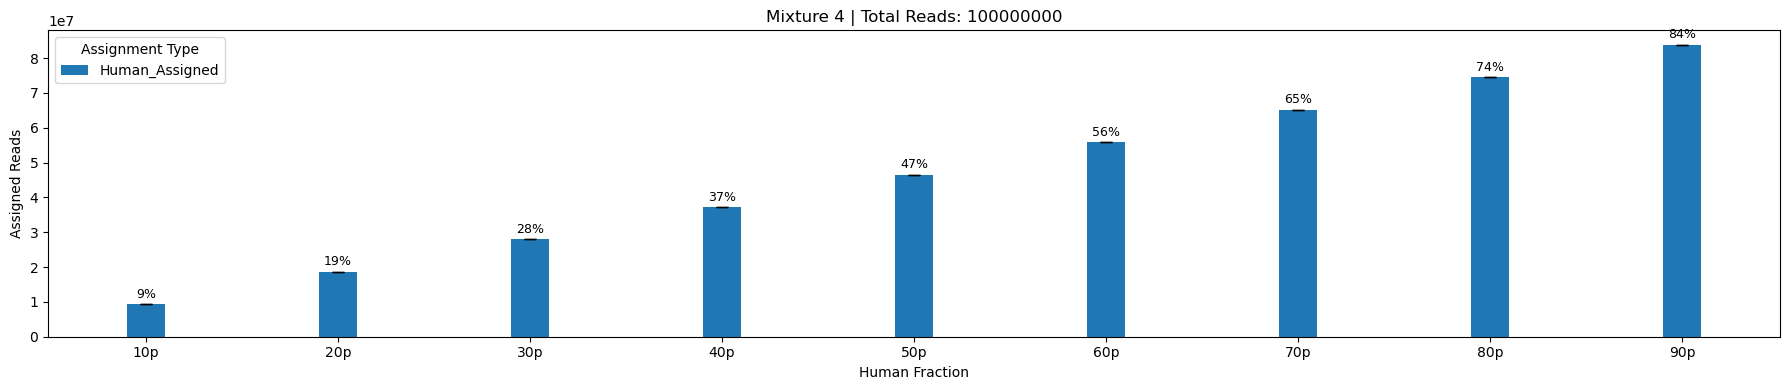

In [5]:
plot_assignment_bars(df, assigned_cols=["Human_Assigned"], save=True, fig_dir=fig_dir)
plot_assignment_bars(df_mm8, assigned_cols=["Human_Assigned"], save=True, fig_dir=fig_dir)

## Confusion Matrix

### Assign TP, TN, FP and FN

In [6]:
df_conf = assign_confusion_matrix(df, method="xenofilter")
df_conf_mm8 = assign_confusion_matrix(df_mm8, method="xenofilter")

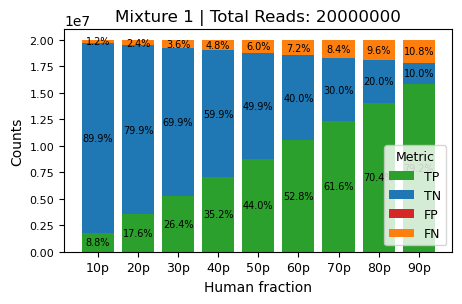

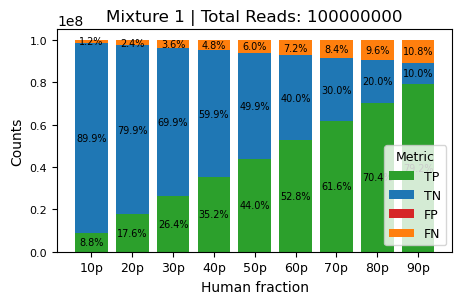

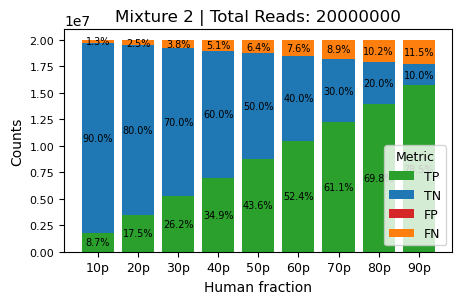

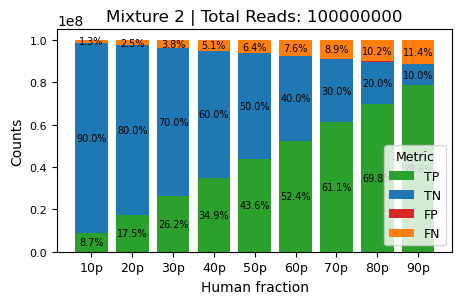

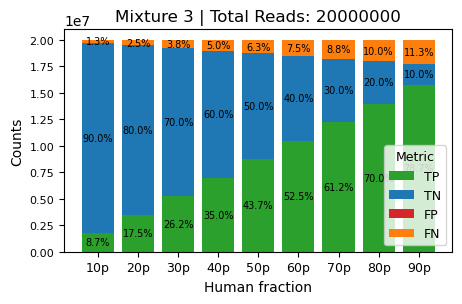

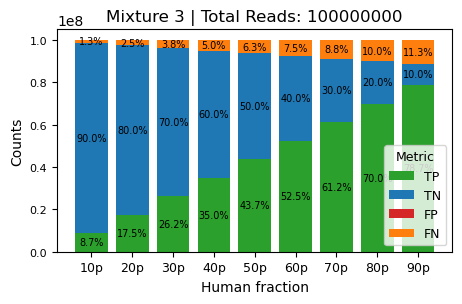

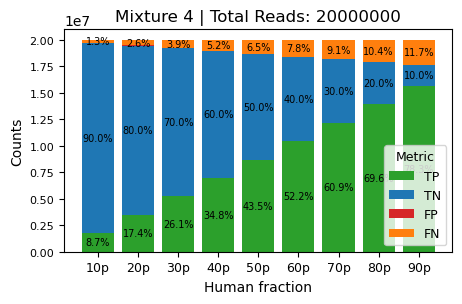

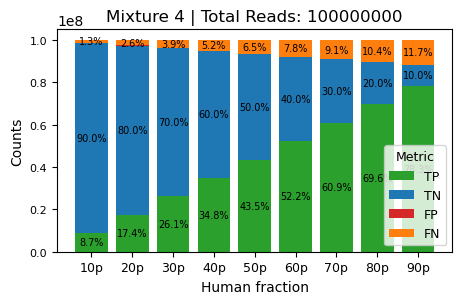

In [7]:
figsize = mm_to_inches((120, 80))

plot_confusion_bar(
    df_conf,
    save = False,
    fig_dir = fig_dir,
    figsize= figsize,
    xlabel_size=10,
    ylabel_size=10,
    xtick_size=9,
    ytick_size=8,
    annotation_size=7
    )


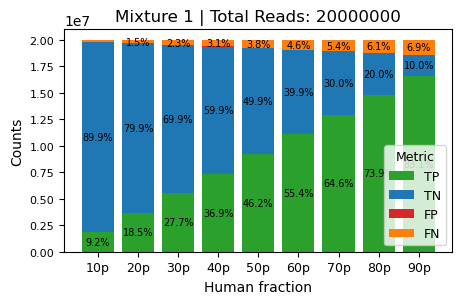

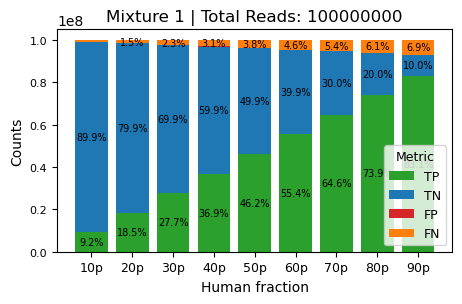

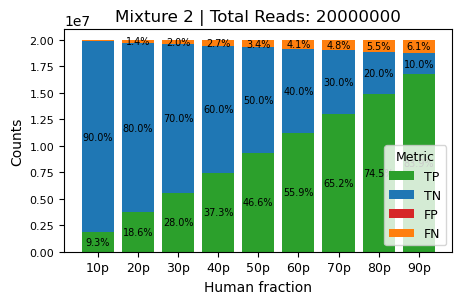

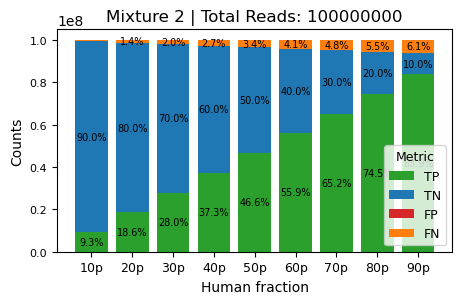

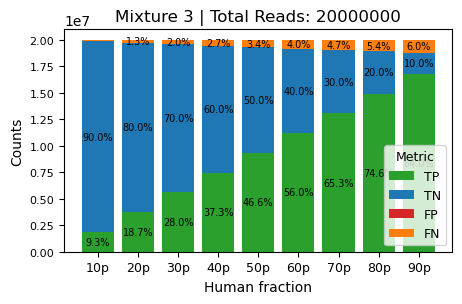

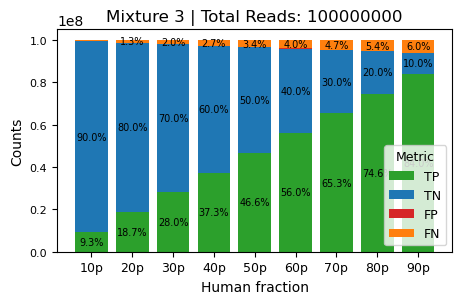

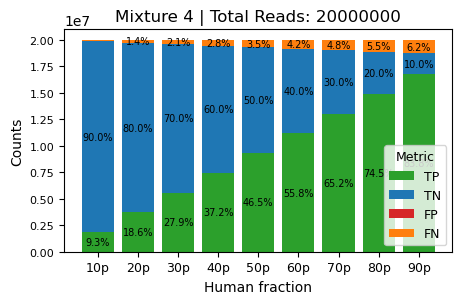

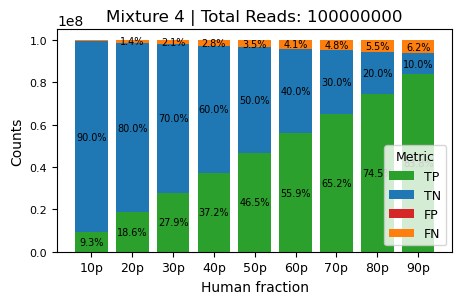

In [8]:
plot_confusion_bar(
    df_conf_mm8,
    save = False,
    fig_dir = fig_dir,
    figsize= figsize,
    xlabel_size=10,
    ylabel_size=10,
    xtick_size=9,
    ytick_size=8,
    annotation_size=7
    )

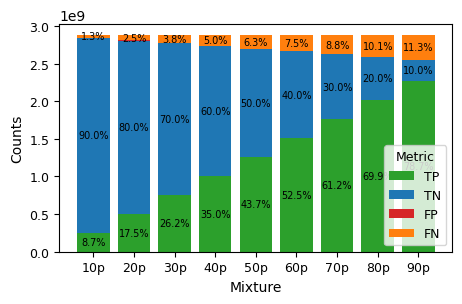

In [9]:
plot_stacked_confusion_bar(
    df_conf,
    save=False,
    figsize= figsize,
    xlabel_size=10,
    ylabel_size=10,
    xtick_size=9,
    ytick_size=9,
    annotation_size=7,
    legend_size=9)

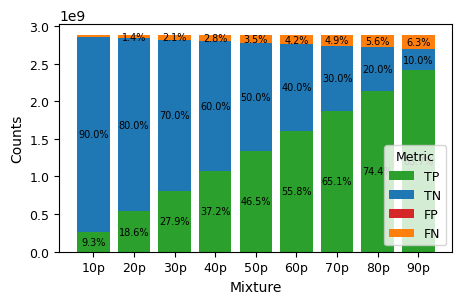

In [10]:
plot_stacked_confusion_bar(
    df_conf_mm8,
    save=False,
    figsize= figsize,
    xlabel_size=10,
    ylabel_size=10,
    xtick_size=9,
    ytick_size=9,
    annotation_size=7,
    legend_size=9)

Xenofilter with MM_Threshold=8 outperforms the default configuration due to less human read loss (false negatives).

From now on, we will only analyze xenofilter_mm8.

## Calculate performance metrics

In [11]:
df_conf_mm8.shape

(432, 16)

In [12]:
df_conf_mm8.head()

,ID,Sample_Prefix,Total_Reads,Mixture,Replicate,Human_Assigned,Human_Human,Human_Mouse,Mouse_Mouse,Mouse_Human,Sample_Name,Human_Ratio,TP,TN,FP,FN
0,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,0,13033680,13032336,1344,5998656,967664,Mixture 4,70.0,13032336,5998656,1344,967664
1,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,1,13032898,13031642,1256,5998744,968358,Mixture 4,70.0,13031642,5998744,1256,968358
2,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,2,13032912,13031562,1350,5998650,968438,Mixture 4,70.0,13031562,5998650,1350,968438
3,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,3,13034322,13032964,1358,5998642,967036,Mixture 4,70.0,13032964,5998642,1358,967036
4,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,4,13034190,13032888,1302,5998698,967112,Mixture 4,70.0,13032888,5998698,1302,967112


In [13]:
df_conf.head()

,ID,Sample_Prefix,Total_Reads,Mixture,Replicate,Human_Assigned,Human_Human,Human_Mouse,Mouse_Mouse,Mouse_Human,Sample_Name,Human_Ratio,TP,TN,FP,FN
0,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,0,12177472,12176488,984,5999016,1823512,Mixture 4,70.0,12176488,5999016,984,1823512
1,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,1,12177236,12176330,906,5999094,1823670,Mixture 4,70.0,12176330,5999094,906,1823670
2,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,2,12175476,12174496,980,5999020,1825504,Mixture 4,70.0,12174496,5999020,980,1825504
3,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,3,12177248,12176274,974,5999026,1823726,Mixture 4,70.0,12176274,5999026,974,1823726
4,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,4,12180104,12179174,930,5999070,1820826,Mixture 4,70.0,12179174,5999070,930,1820826


In [15]:
df_metrics = calculate_metrics(df_conf_mm8)
df_metrics.head(3)[["Sample_Name", "Total_Reads", "Mixture", "Replicate", "Human_Loss", "Contamination_Rate", "Mouse_Leakage"]]

,Sample_Name,Total_Reads,Mixture,Replicate,Human_Loss,Contamination_Rate,Mouse_Leakage
0,Mixture 4,20000000,70p,0,0.069119,0.000103,0.000224
1,Mixture 4,20000000,70p,1,0.069168,0.000096,0.000209
2,Mixture 4,20000000,70p,2,0.069174,0.000104,0.000225


## Visualize performance metrics

### By total reads, for each sample

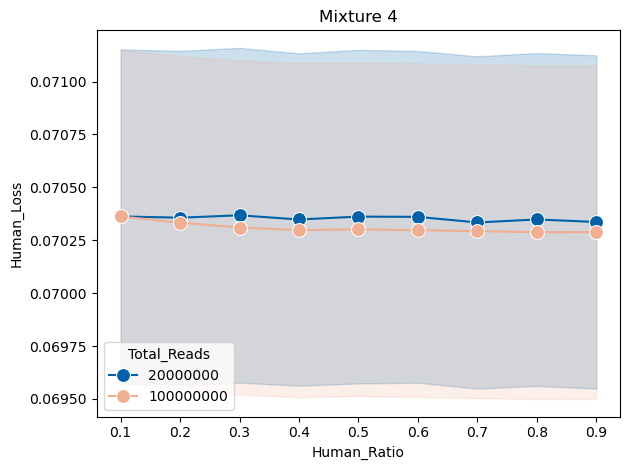

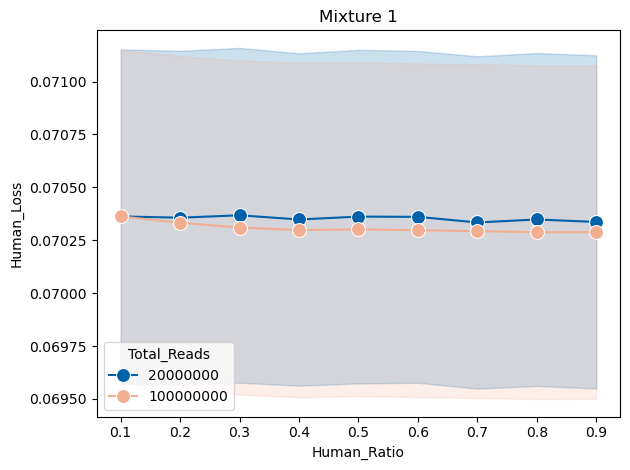

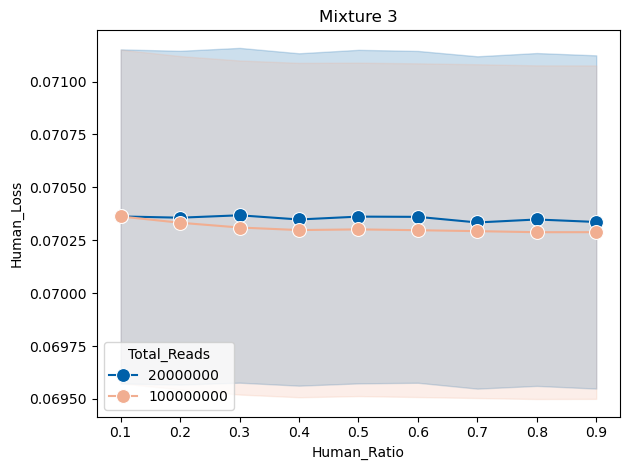

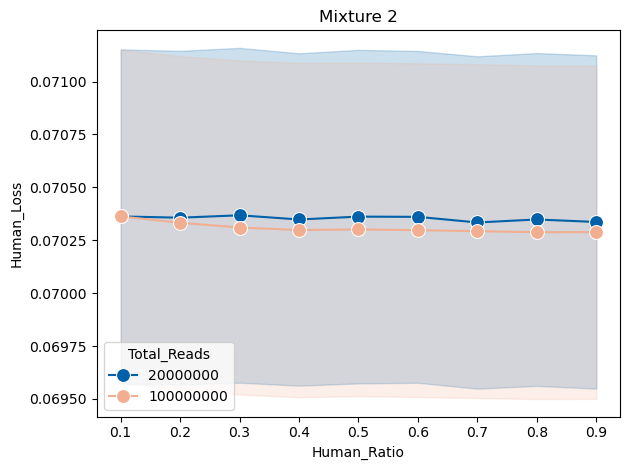

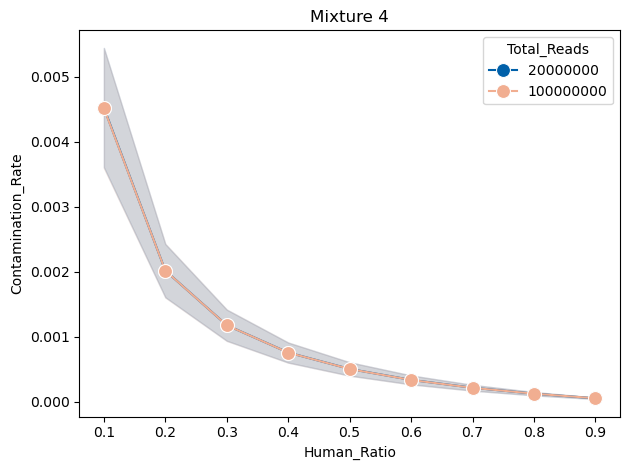

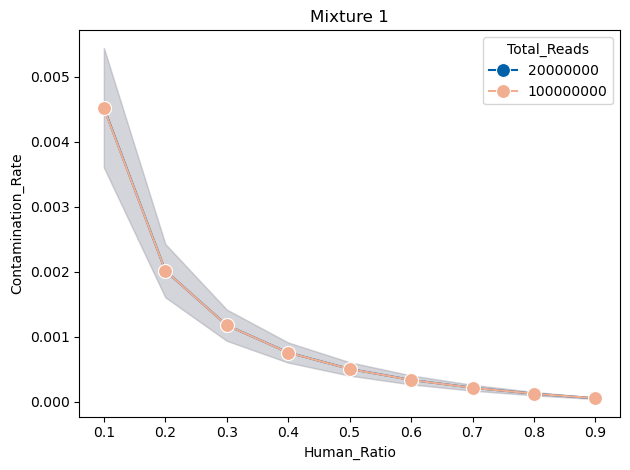

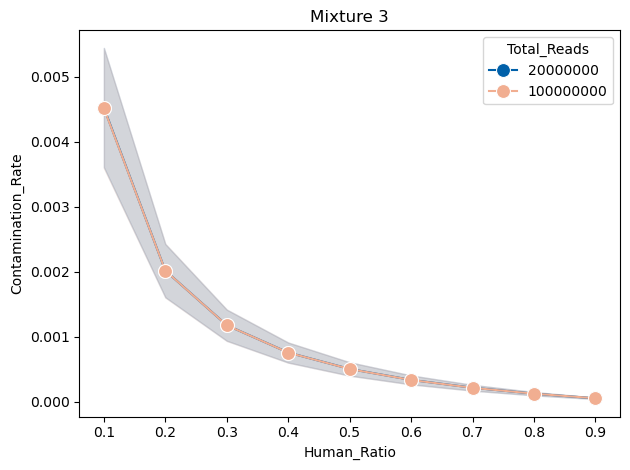

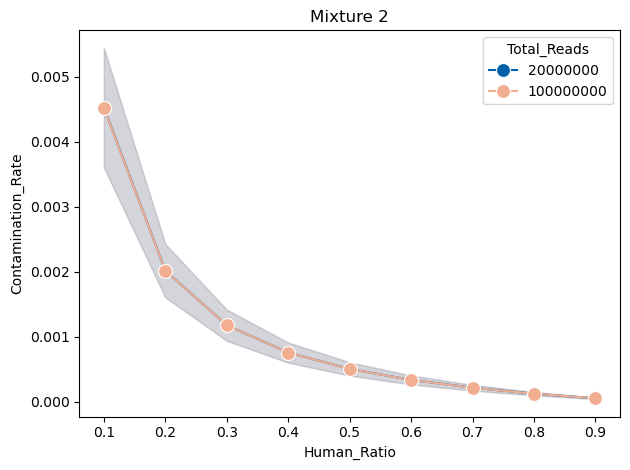

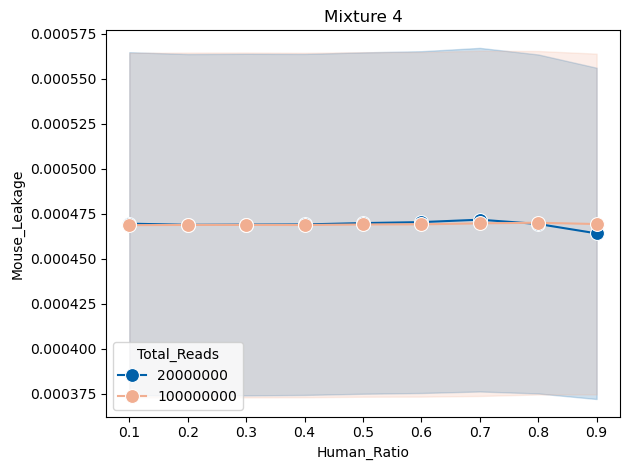

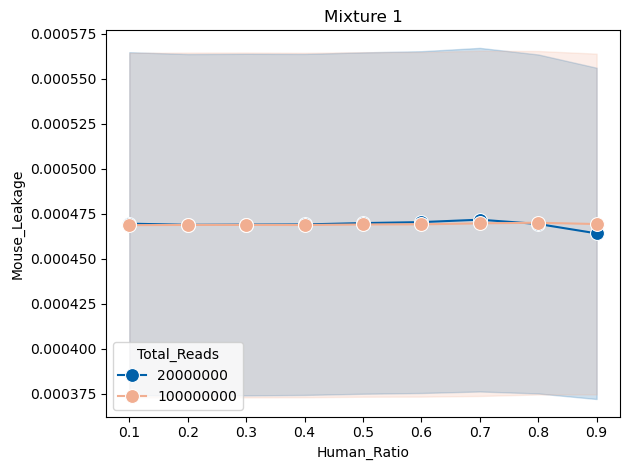

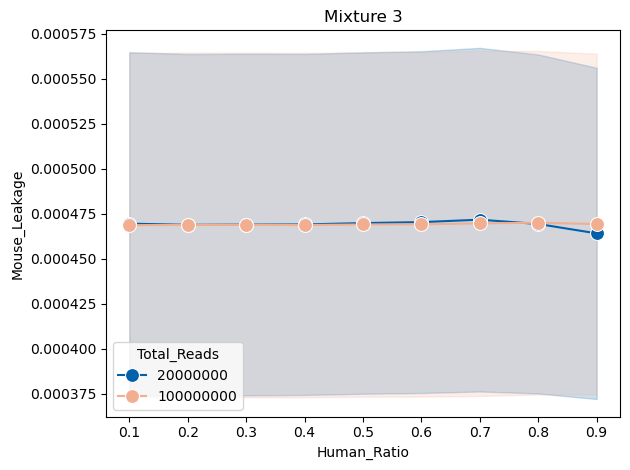

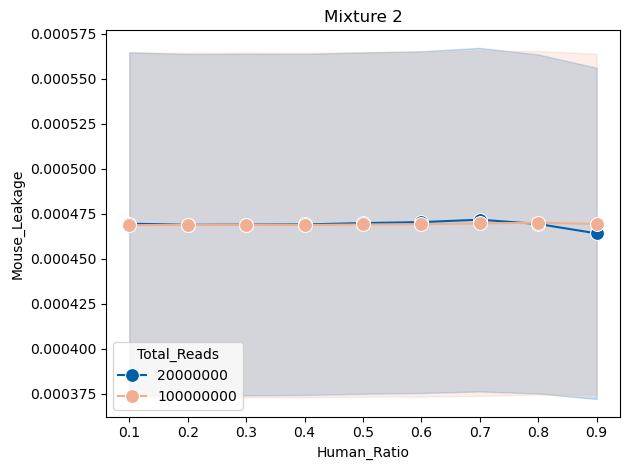

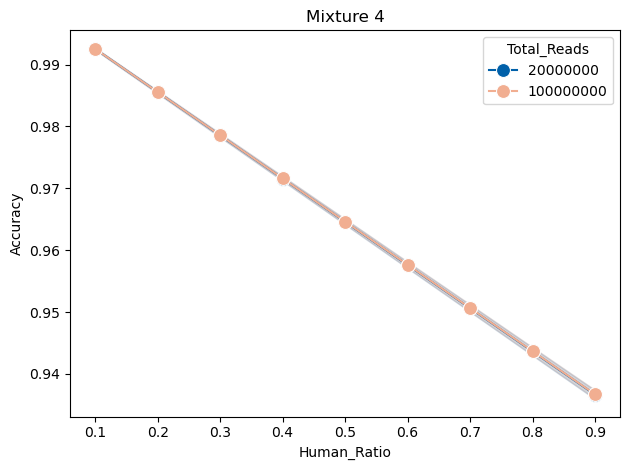

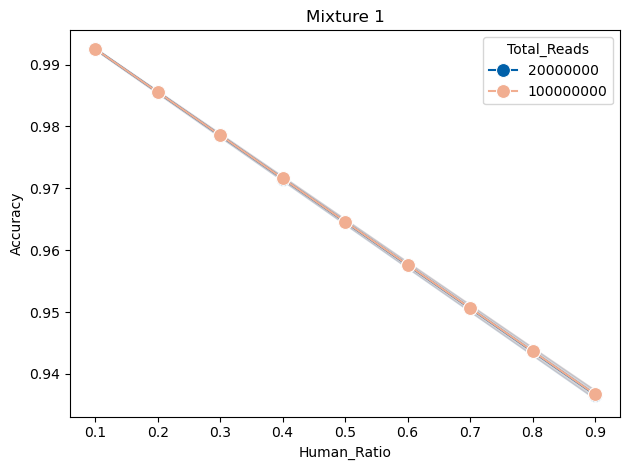

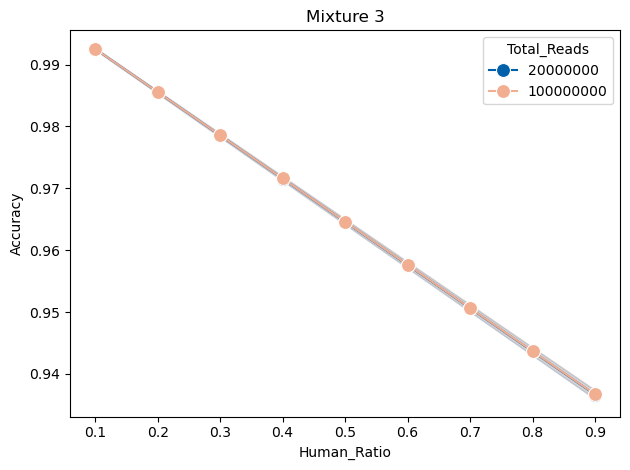

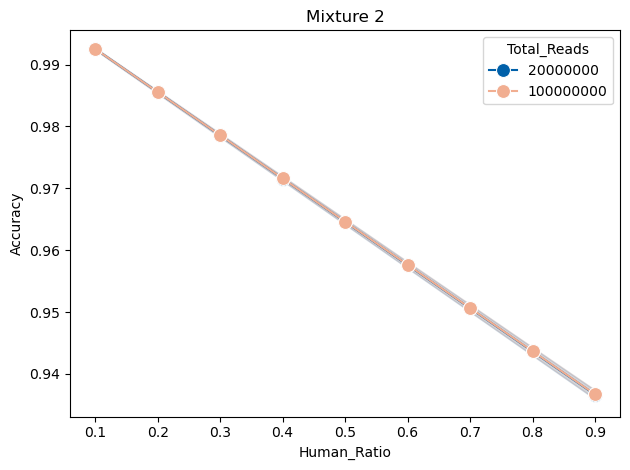

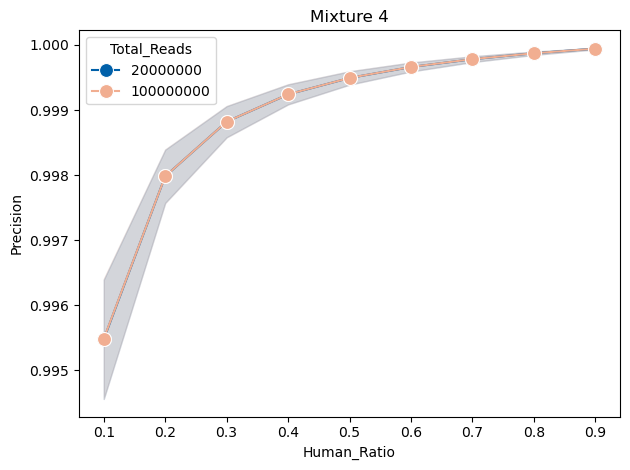

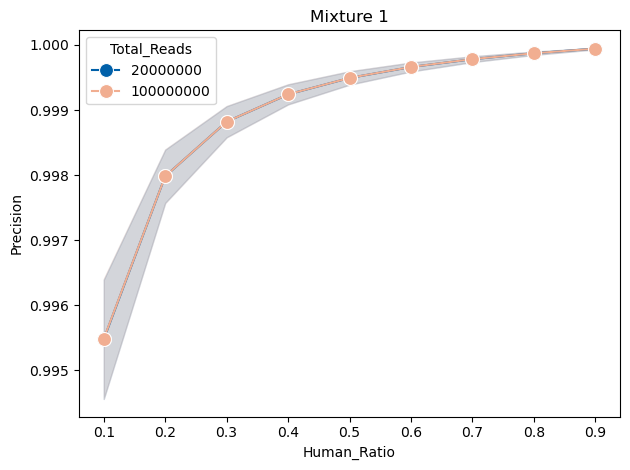

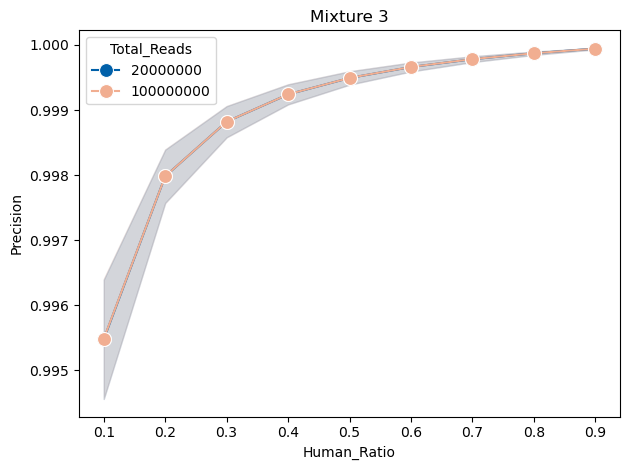

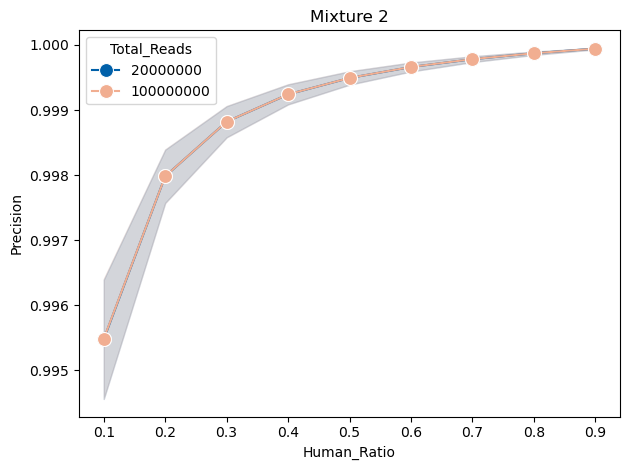

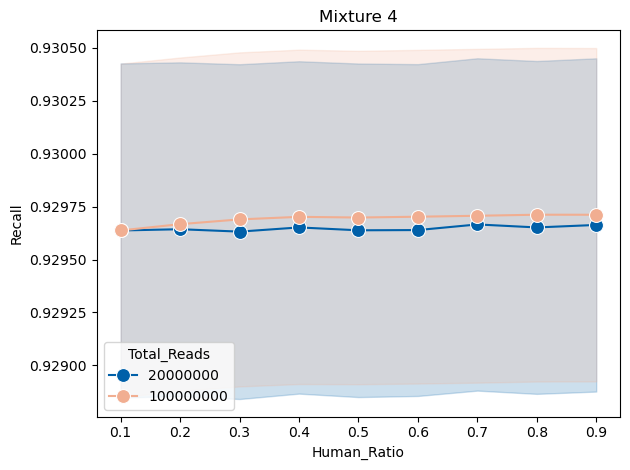

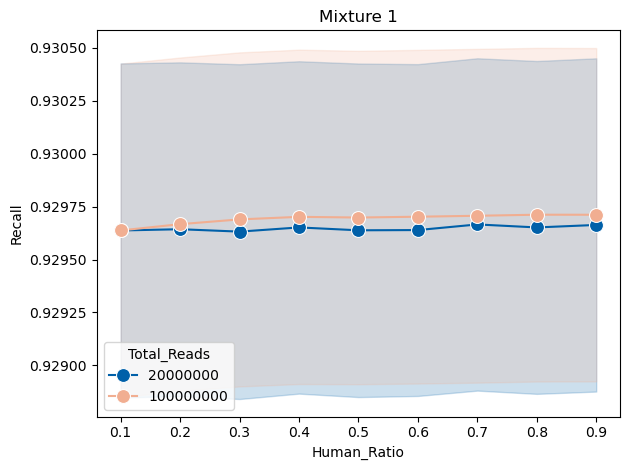

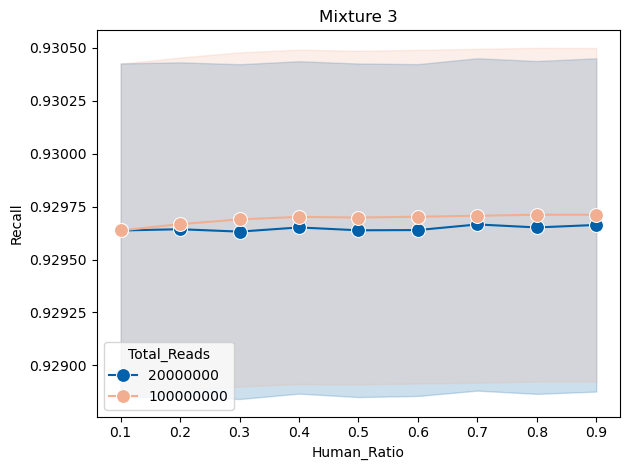

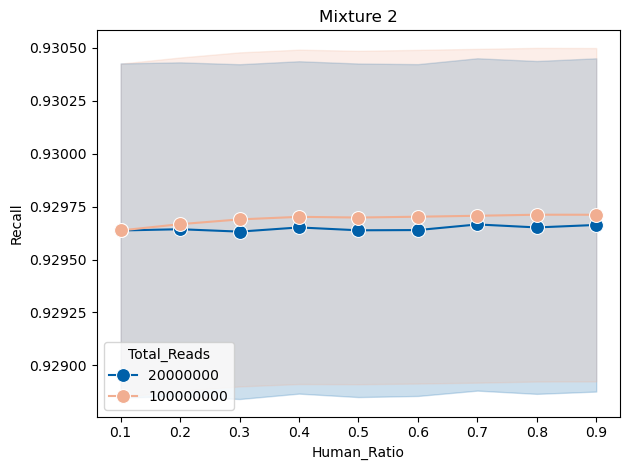

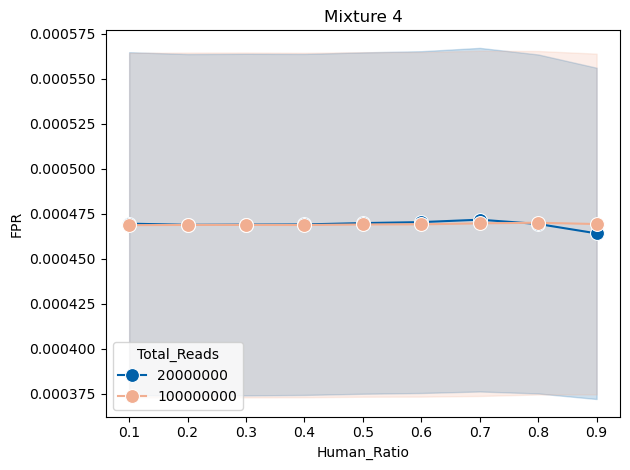

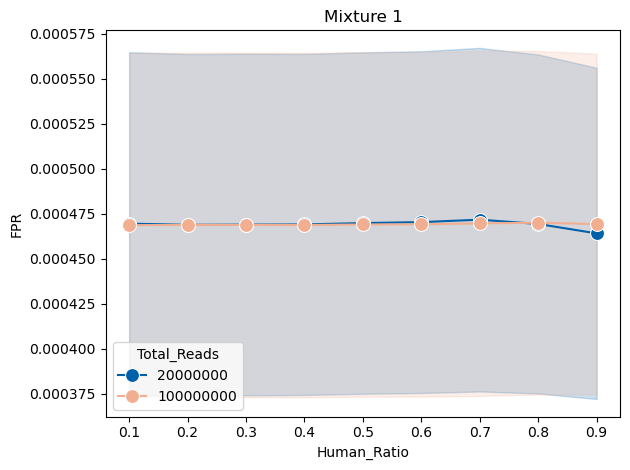

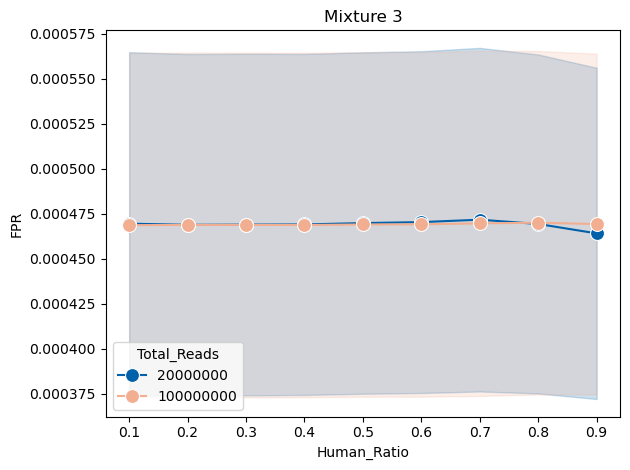

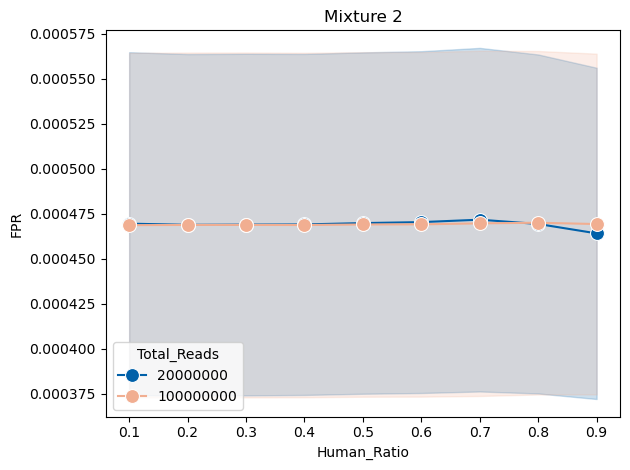

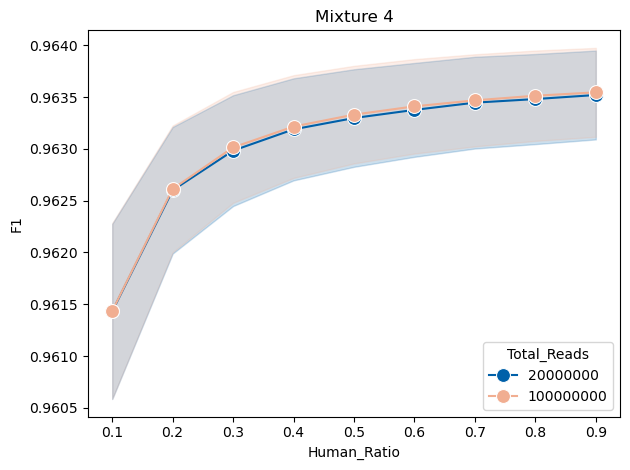

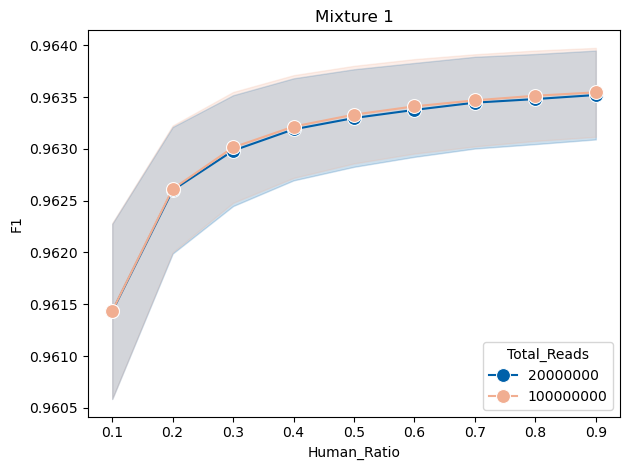

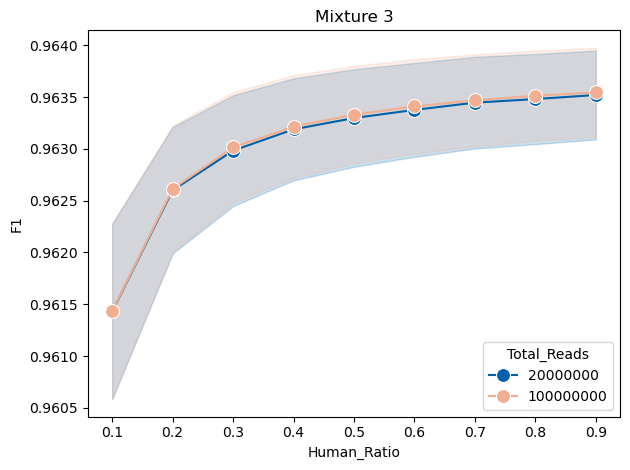

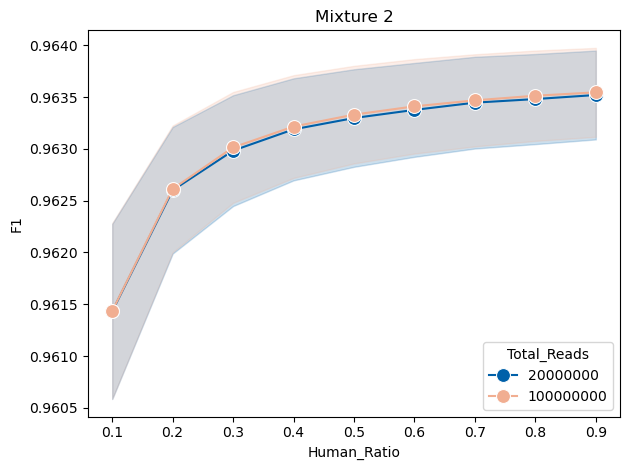

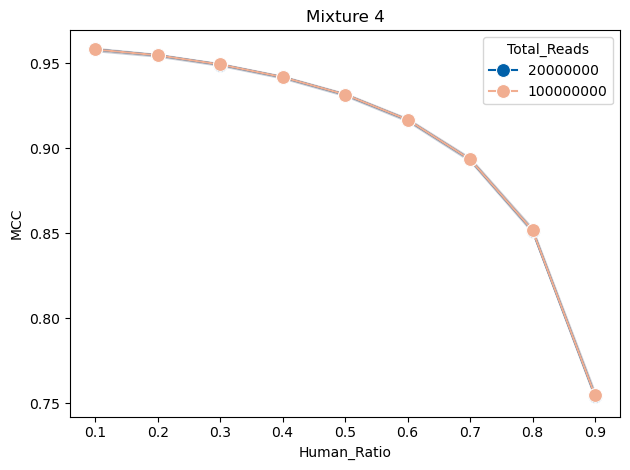

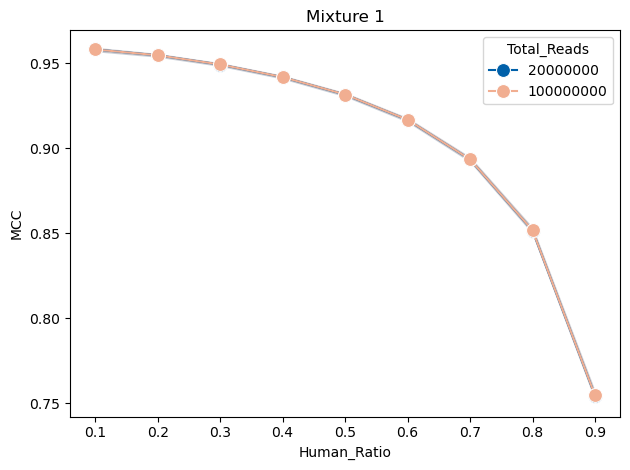

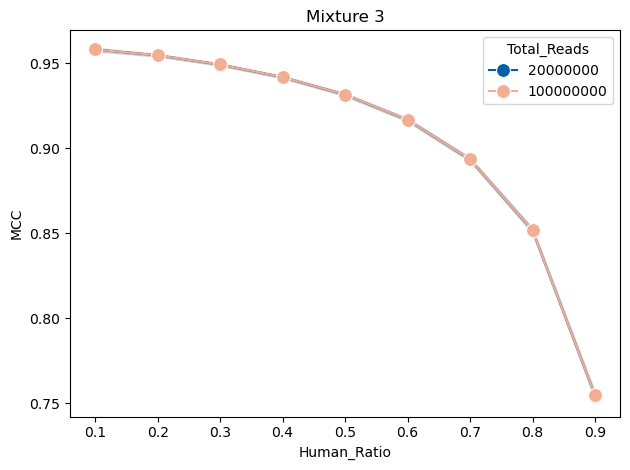

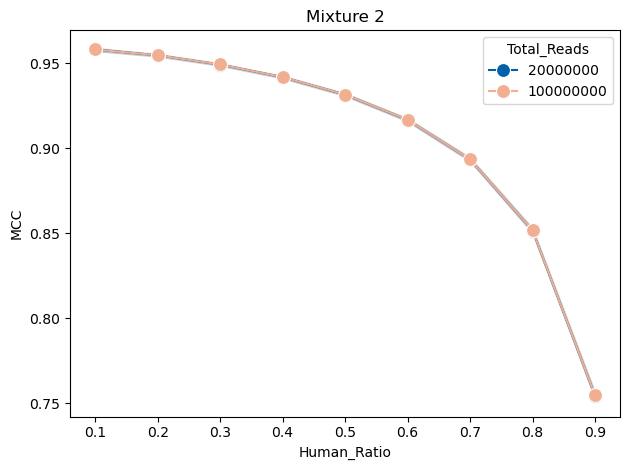

In [16]:
errorplot_by_reads(df_metrics, metric="Human_Loss", save=True, fig_dir=fig_dir, palette=dkfz_colors)
errorplot_by_reads(df_metrics, metric="Contamination_Rate", save=True, fig_dir=fig_dir, palette=dkfz_colors)
errorplot_by_reads(df_metrics, metric="Mouse_Leakage", save=True, fig_dir=fig_dir, palette=dkfz_colors)

errorplot_by_reads(df_metrics, metric="Accuracy", save=True, fig_dir=fig_dir, palette=dkfz_colors)
errorplot_by_reads(df_metrics, metric="Precision", save=True, fig_dir=fig_dir,  palette=dkfz_colors)
errorplot_by_reads(df_metrics, metric="Recall", save=True, fig_dir=fig_dir,  palette=dkfz_colors)
errorplot_by_reads(df_metrics, metric="FPR", save=True, fig_dir=fig_dir,  palette=dkfz_colors)
errorplot_by_reads(df_metrics, metric="F1", save=True, fig_dir=fig_dir,  palette=dkfz_colors)
errorplot_by_reads(df_metrics, metric="MCC", save=True, fig_dir=fig_dir,  palette=dkfz_colors);


### Across samples

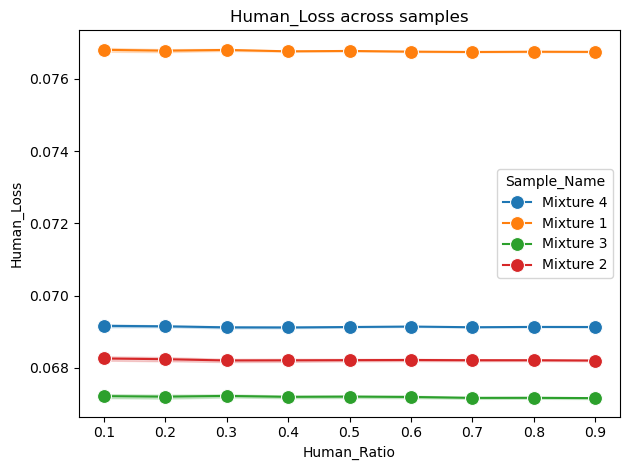

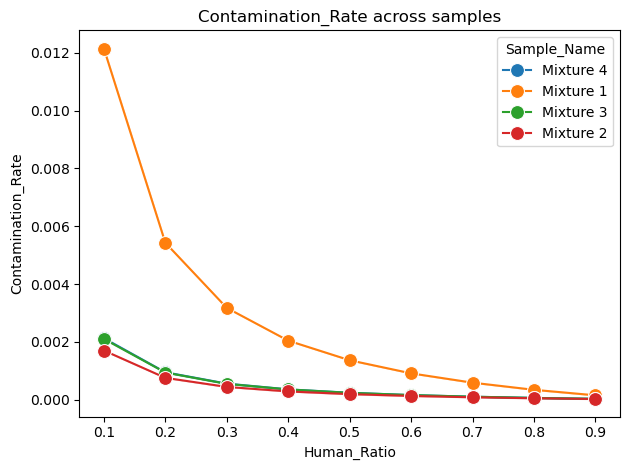

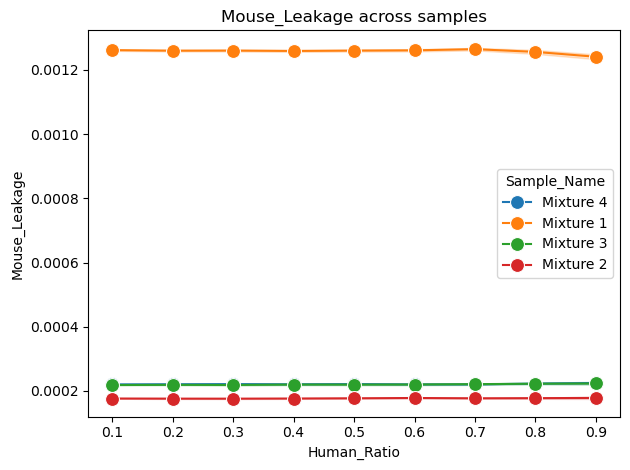

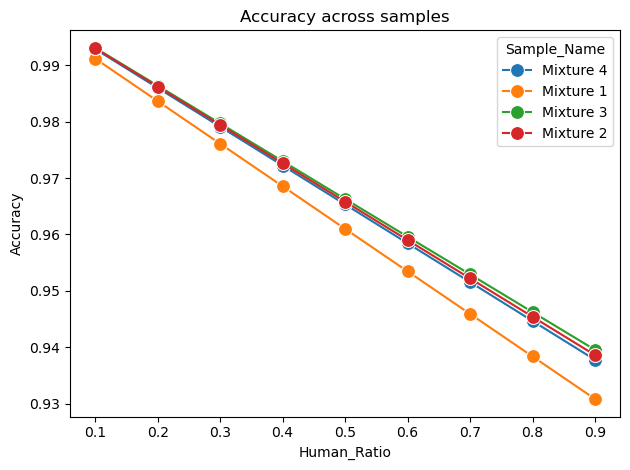

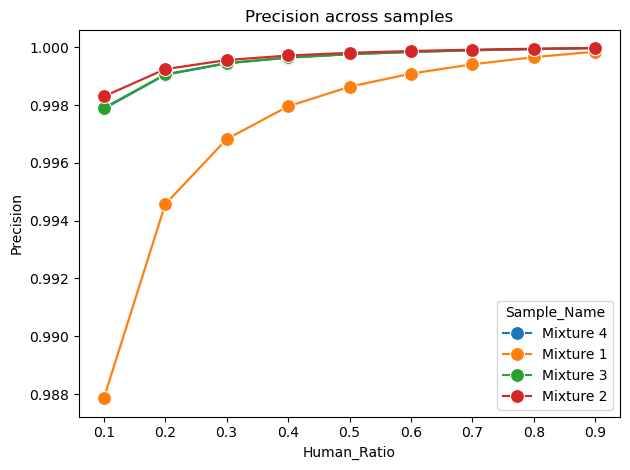

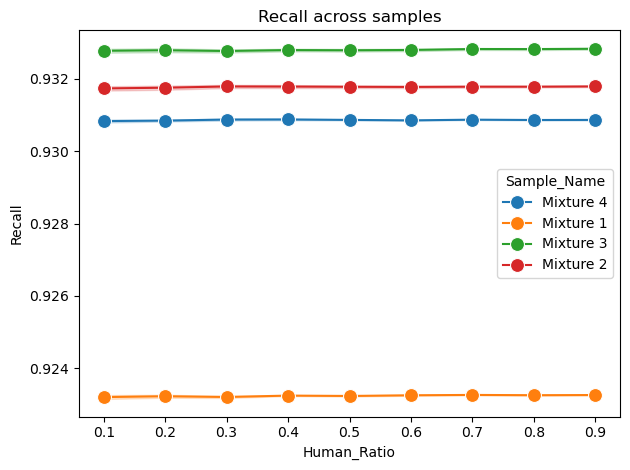

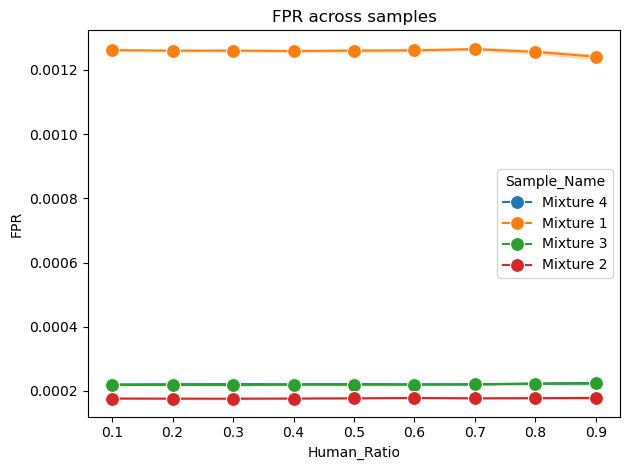

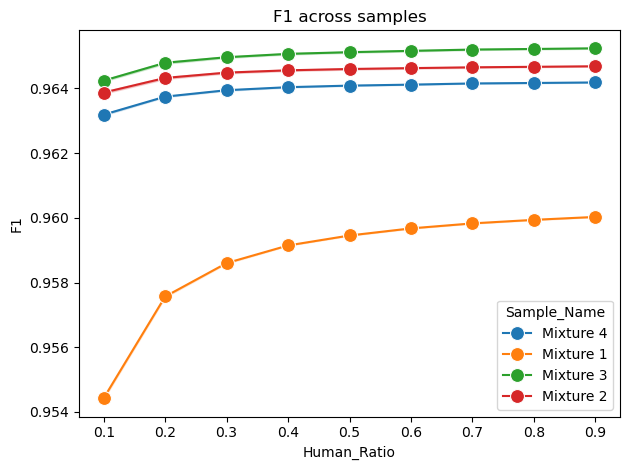

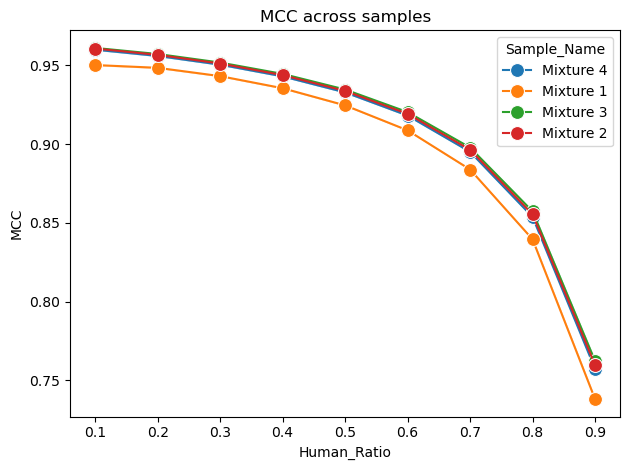

In [17]:
errorplot_by_sample(df_metrics, metric="Human_Loss")
errorplot_by_sample(df_metrics, metric="Contamination_Rate")
errorplot_by_sample(df_metrics, metric="Mouse_Leakage")
errorplot_by_sample(df_metrics, metric="Accuracy")
errorplot_by_sample(df_metrics, metric="Precision")
errorplot_by_sample(df_metrics, metric="Recall")
errorplot_by_sample(df_metrics, metric="FPR")
errorplot_by_sample(df_metrics, metric="F1")
errorplot_by_sample(df_metrics, metric="MCC")

### Boxplots across samples

In [18]:
df_metrics["Score"]

0      0.979192
1      0.979182
2      0.979175
3      0.979205
4      0.979206
         ...   
427    0.979520
428    0.979509
429    0.979505
430    0.979516
431    0.979523
Name: Score, Length: 432, dtype: float64

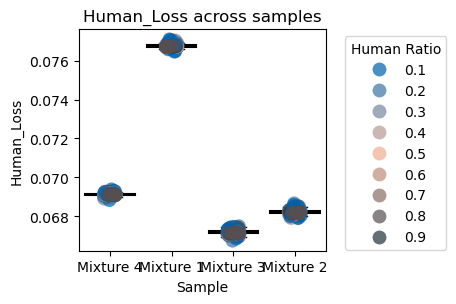

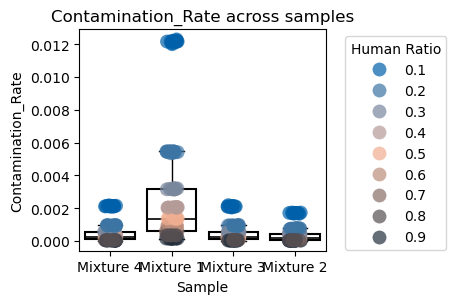

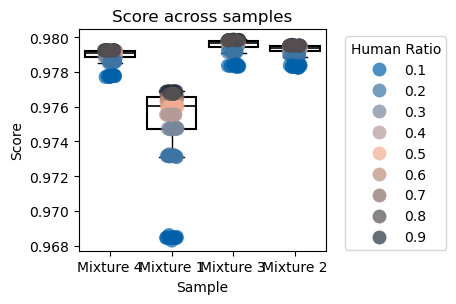

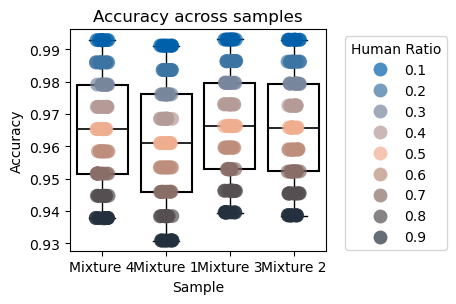

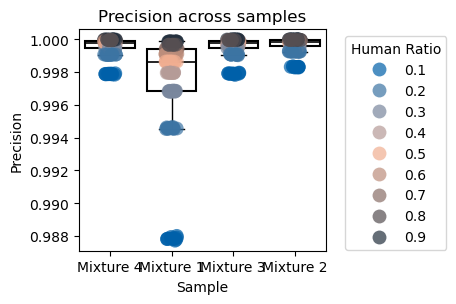

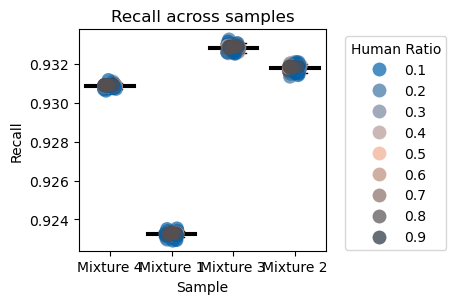

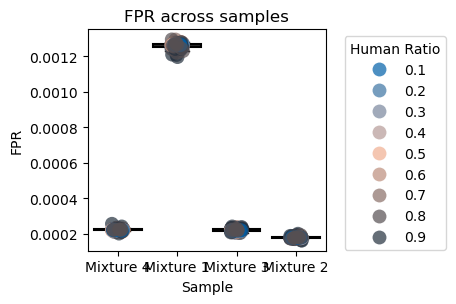

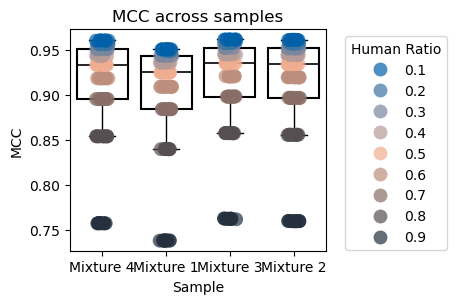

In [19]:

figsize= mm_to_inches((120, 80))
metrics = ["Human_Loss", "Contamination_Rate", "Score", "Accuracy", "Precision", "Recall", "FPR", "MCC"]
for metric in metrics:
    boxplot_by_samples(df_metrics, metric=metric, figsize=figsize)



## Save DataFrame

In [20]:
df_metrics["Method"] = "XenofilteR"
out_dir = Path.cwd() / "results"
out_dir.mkdir(exist_ok=True)

df_metrics.to_csv(out_dir / "xenofilter.csv", index=False)